# Bore Oil Production Time-Series Forecasting

This notebook explores daily Volve production data and compares ARIMA, XGBoost, and LSTM forecasts for bore oil volume. It keeps exploratory analysis and model experiments together; reusable workflow components are also available in `src/`.

**Target:** `BORE_OIL_VOL` for well `15/9-F-12`  
**Input:** the Volve production workbook  
**Evaluation:** chronological train, validation, and test periods

## Notebook Guide

The workflow loads and filters production records, inspects and cleans the selected well's data, explores time-series behavior, then trains and evaluates three forecasting approaches. Run cells from top to bottom because later model cells reuse variables created earlier.

The data path is set in the first data-loading section. Change it there if the workbook is stored elsewhere.

## Setup and Data

### Imports and Input Path

Load the analysis libraries and set the path to the Volve workbook. The next cells read the daily and monthly sheets, select production-only wells, retain well `15/9-F-12`, and split its records chronologically so the latest 15% is held out for testing.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
import polars as pl


from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    GroupKFold,
    cross_val_score,
)
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor


import numpy as np
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import seaborn as sns

import statsmodels.api as sm
import optuna 




d:\GitHub\.ML_Environment\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load and Select the Production Series

Load workbook sheets, identify wellbores whose flow records are production-only, select `15/9-F-12`, and make a chronological 85/15 train/test split.

In [2]:
workbook_path=(r"D:\DataSets\Production_data\Volve production data.xlsx")

In [3]:
workbook_sheets = pd.read_excel(path, sheet_name=None)
daily_production_data = workbook_sheets["Daily Production Data"]
monthly_production_data = workbook_sheets["Monthly Production Data"]


In [ ]:
production_only_well_names = (                                    
    daily_production_data.groupby("NPD_WELL_BORE_NAME")["FLOW_KIND"]
    .agg(set)
    .loc[lambda x: x == {"production"}]
)

production_only_well_names

NPD_WELL_BORE_NAME
15/9-F-1 C     {production}
15/9-F-11      {production}
15/9-F-12      {production}
15/9-F-14      {production}
15/9-F-15 D    {production}
Name: FLOW_KIND, dtype: object

In [5]:
production_records = daily_production_data[daily_production_data["NPD_WELL_BORE_NAME"].isin(production_only_well_names.index.tolist())]
target_well_data= production_records[production_records["NPD_WELL_BORE_NAME"] == "15/9-F-12"]

In [6]:
train_test_split_index = int(len(target_well_data) * 0.85)

train_df = target_well_data.iloc[:train_test_split_index].copy()
test_df = target_well_data.iloc[train_test_split_index:].copy()

In [7]:
train_df.set_index("DATEPRD", inplace=True)
test_df.set_index("DATEPRD", inplace=True)

In [8]:
test_df.index

DatetimeIndex(['2015-06-17', '2015-06-18', '2015-06-19', '2015-06-20',
               '2015-06-21', '2015-06-22', '2015-06-23', '2015-06-24',
               '2015-06-25', '2015-06-26',
               ...
               '2016-09-08', '2016-09-09', '2016-09-10', '2016-09-11',
               '2016-09-12', '2016-09-13', '2016-09-14', '2016-09-15',
               '2016-09-16', '2016-09-17'],
              dtype='datetime64[ns]', name='DATEPRD', length=459, freq=None)

## Exploratory Data Analysis

Inspect the selected well's columns, time coverage, missing values, and production measures before modeling.

### Question and Target

The task is to forecast daily bore oil volume from its historical values. The notebook first checks the selected well and production records, then examines the target's distribution and time pattern.

In [9]:
train_df.columns

Index(['WELL_BORE_CODE', 'NPD_WELL_BORE_CODE', 'NPD_WELL_BORE_NAME',
       'NPD_FIELD_CODE', 'NPD_FIELD_NAME', 'NPD_FACILITY_CODE',
       'NPD_FACILITY_NAME', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE',
       'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING', 'AVG_ANNULUS_PRESS',
       'AVG_CHOKE_SIZE_P', 'AVG_CHOKE_UOM', 'AVG_WHP_P', 'AVG_WHT_P',
       'DP_CHOKE_SIZE', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL',
       'BORE_WI_VOL', 'FLOW_KIND', 'WELL_TYPE'],
      dtype='object')

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2597 entries, 2008-02-12 to 2015-06-16
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   WELL_BORE_CODE            2597 non-null   object 
 1   NPD_WELL_BORE_CODE        2597 non-null   int64  
 2   NPD_WELL_BORE_NAME        2597 non-null   object 
 3   NPD_FIELD_CODE            2597 non-null   int64  
 4   NPD_FIELD_NAME            2597 non-null   object 
 5   NPD_FACILITY_CODE         2597 non-null   int64  
 6   NPD_FACILITY_NAME         2597 non-null   object 
 7   ON_STREAM_HRS             2597 non-null   float64
 8   AVG_DOWNHOLE_PRESSURE     2591 non-null   float64
 9   AVG_DOWNHOLE_TEMPERATURE  2591 non-null   float64
 10  AVG_DP_TUBING             2591 non-null   float64
 11  AVG_ANNULUS_PRESS         2584 non-null   float64
 12  AVG_CHOKE_SIZE_P          2553 non-null   float64
 13  AVG_CHOKE_UOM             2597 non-null   obj

In [11]:
train_df["NPD_WELL_BORE_NAME"].value_counts()

NPD_WELL_BORE_NAME
15/9-F-12    2597
Name: count, dtype: int64

In [12]:
train_df["FLOW_KIND"].value_counts()

FLOW_KIND
production    2597
Name: count, dtype: int64

### Inspect and Clean the Selected Well

Review the training data shape, missingness, and relevant production variables. The workflow removes the water-injection column and rows with non-positive oil volume; rows missing choke-size information are removed from training data.

In [13]:
train_df.shape

(2597, 23)

In [14]:
train_df.isna().sum()

WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE          6
AVG_DOWNHOLE_TEMPERATURE       6
AVG_DP_TUBING                  6
AVG_ANNULUS_PRESS             13
AVG_CHOKE_SIZE_P              44
AVG_CHOKE_UOM                  0
AVG_WHP_P                      0
AVG_WHT_P                      0
DP_CHOKE_SIZE                  0
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 2597
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

### Data Quality and Preparation

Check missing values and basic target/feature ranges. The preparation below drops the unused water-injection field, filters non-positive oil records, and imputes remaining numeric gaps using training-set medians.

In [15]:
columns_to_drop= ["BORE_WI_VOL"]

In [16]:
train_df.drop(columns_to_drop, axis=1 , inplace=True)
test_df.drop(columns_to_drop, axis=1 , inplace=True)

In [17]:
if "BORE_WI_VOL" in train_df.columns:
    print(f"{columns_to_drop} has been dropped from the DataFrame.")
else:
    print(f"{columns_to_drop} is not present in the DataFrame.")

['BORE_WI_VOL'] is not present in the DataFrame.


In [21]:
train_df= train_df[train_df["BORE_OIL_VOL"] > 0 ]
test_df= test_df[test_df["BORE_OIL_VOL"] > 0 ]

In [23]:
train_df["BORE_OIL_VOL"].describe()

count    2417.000000
mean     1838.182317
std      1712.959397
min         1.300000
25%       536.060000
50%      1095.940000
75%      3143.370000
max      5901.840000
Name: BORE_OIL_VOL, dtype: float64

### Impute Remaining Numeric Values

Median values are learned from the training partition and applied to both train and test data, avoiding fitting the imputer on the held-out test partition.

In [24]:
def process_data(train_df, test_df):
    numeric_cols = train_df.select_dtypes(include="number").columns

    imputer = SimpleImputer(strategy="median")
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df[numeric_cols] = imputer.fit_transform(train_df[numeric_cols])
    test_df[numeric_cols] = imputer.transform(test_df[numeric_cols])

    return train_df, test_df


In [25]:
train_df, test_df= process_data(train_df,test_df)

In [26]:
# def scalr_data(train_df, test_df):
#     numeric_cols = train_df.select_dtypes(include="number").columns
#     scalr = StandardScaler()

#     train_df[numeric_cols] = scalr.fit_transform(train_df[numeric_cols])
#     test_df[numeric_cols] = scalr.transform(test_df[numeric_cols])

#     return train_df, test_df

In [27]:
# train_df, test_df= scalr_data(train_df,test_df)

### Explore Distributions and Trends

The following plots show selected pressure/choke distributions, daily production, annual peaks, and the expanding mean. These views help identify scale, trend, and operational variation before forecasting.

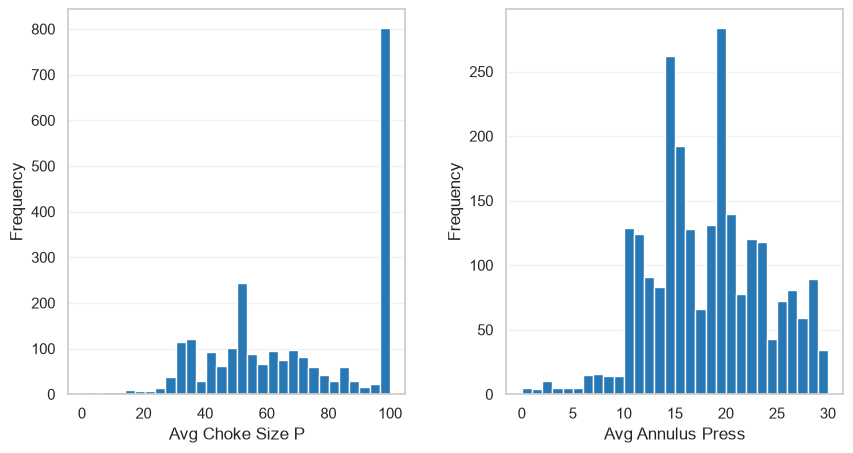

In [28]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
axes = train_df.hist(bins=30, column=["AVG_CHOKE_SIZE_P", "AVG_ANNULUS_PRESS"], grid=False, figsize=(10, 5), color="#2878B5", edgecolor="white")
for ax in axes.ravel():
    ax.set_xlabel(ax.get_title().replace("_", " ").title())
    ax.set_ylabel("Frequency")
    ax.set_title("")
    ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
for index, ax in enumerate(axes.ravel(), start=1):
    ax.figure.savefig(f"figures/01_production_feature_distribution_{index}.png", dpi=300, bbox_inches="tight")


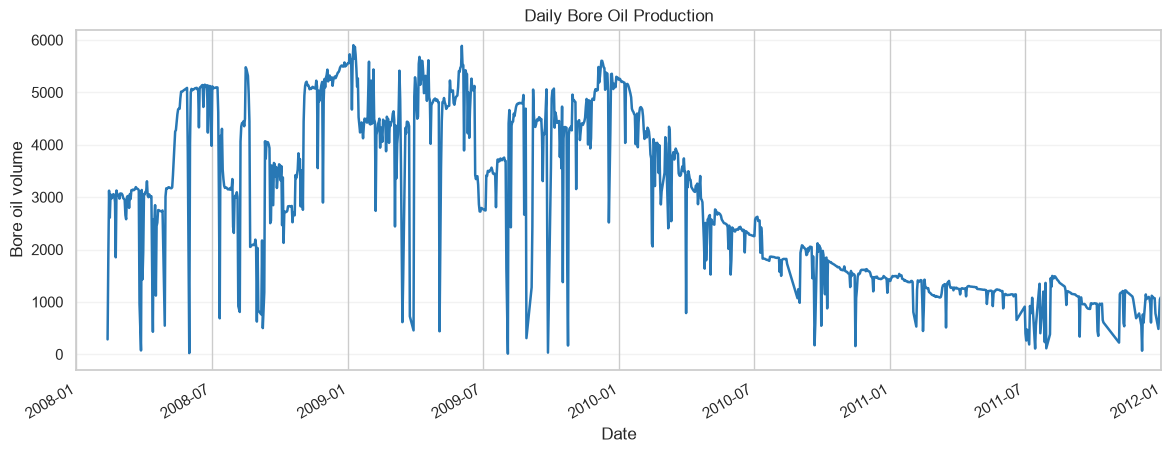

In [29]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].plot(xlim=["2008-01-01", "2012"], figsize=(14, 5), title="Daily Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/02_daily_bore_oil_production.png", dpi=300, bbox_inches="tight")


In [30]:
pd.DataFrame(train_df["BORE_OIL_VOL"].resample(rule="YE").max())

,BORE_OIL_VOL
DATEPRD,
2008-12-31,5571.07
2009-12-31,5901.84
2010-12-31,5261.93
2011-12-31,1534.90
2012-12-31,1377.09
2013-12-31,618.44
2014-12-31,281.94
2015-12-31,1162.07


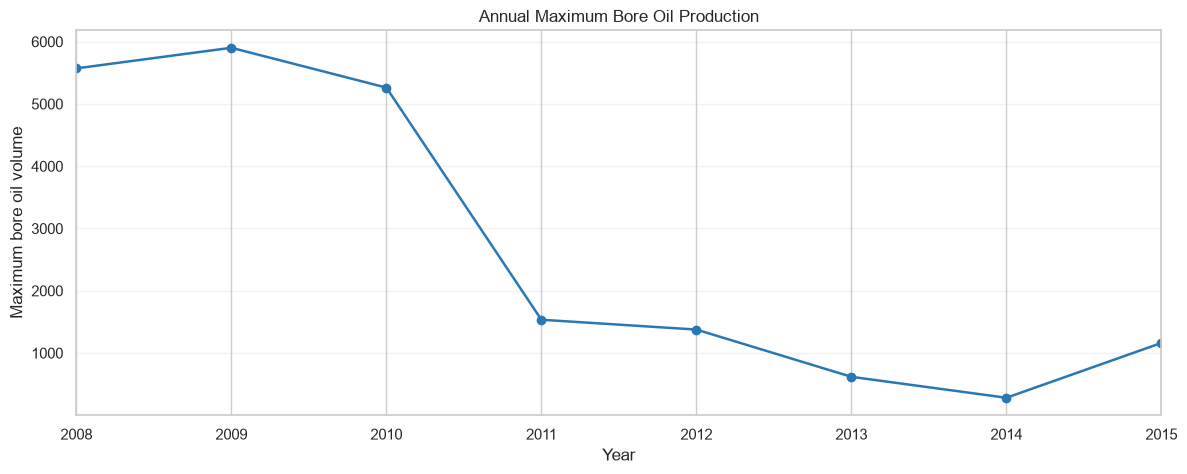

In [31]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", linewidth=1.8, marker="o")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/03_annual_maximum_bore_oil_production.png", dpi=300, bbox_inches="tight")


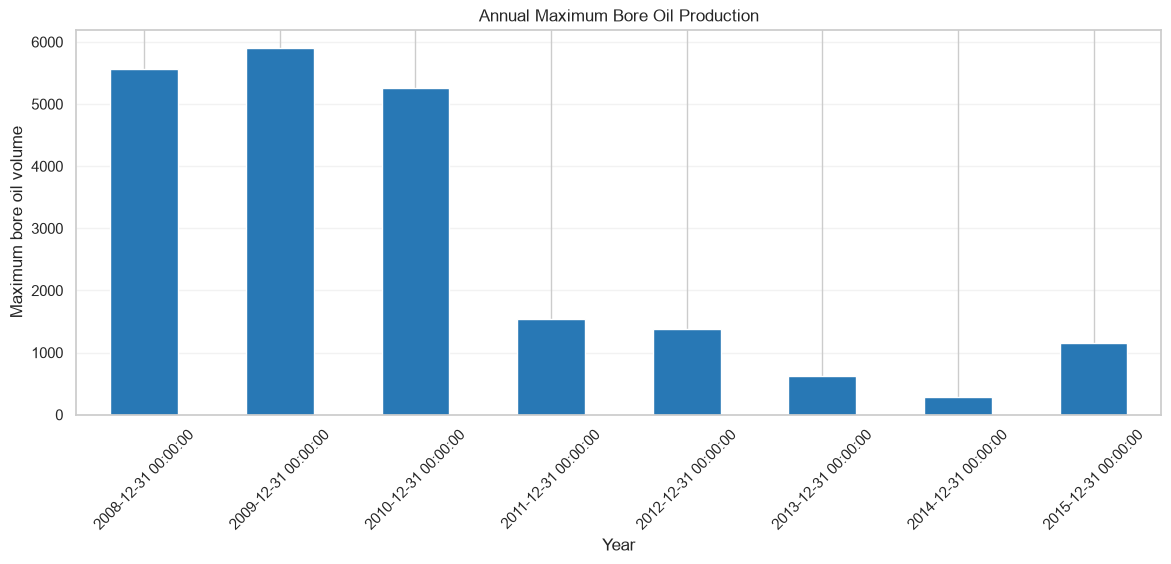

In [32]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].resample(rule="YE").max().plot(kind="bar", figsize=(14, 5), title="Annual Maximum Bore Oil Production", color="#2878B5", edgecolor="white")
ax.set(xlabel="Year", ylabel="Maximum bore oil volume")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/04_annual_maximum_bore_oil_production_bar.png", dpi=300, bbox_inches="tight")


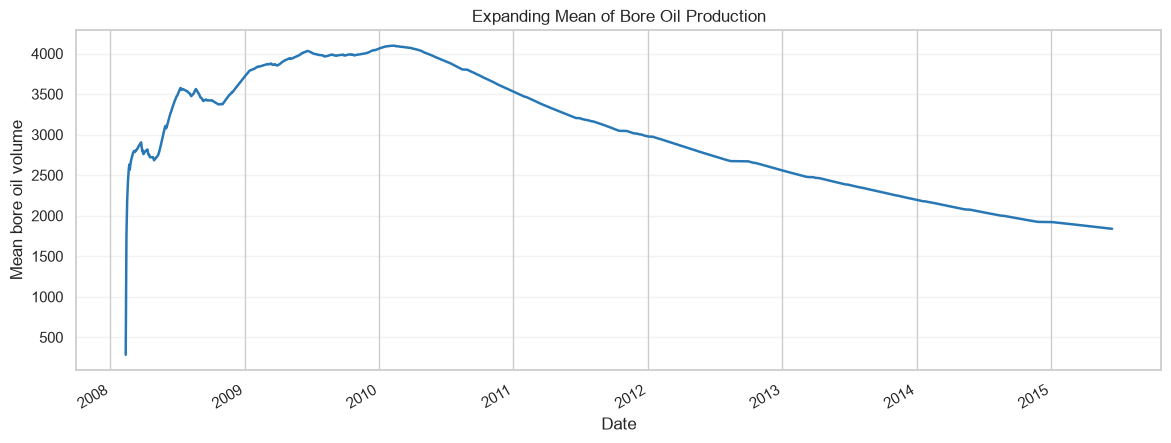

In [33]:
## best plot so far
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["BORE_OIL_VOL"].expanding().mean().plot(xlabel="Date", ylabel="Mean bore oil volume", figsize=(14, 5), title="Expanding Mean of Bore Oil Production", color="#2878B5", linewidth=1.8)
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/06_expanding_mean_bore_oil_production.png", dpi=300, bbox_inches="tight")


## Time-Series Diagnostics

Difference the training target, inspect its change over time, apply an Augmented Dickey–Fuller stationarity check, and review seasonal decomposition plus autocorrelation plots. These diagnostics inform the ARIMA setup.

### Stationarity Diagnostics

The next cells difference the training target and assess whether its behavior is closer to stationary. The raw production target remains available for the forecasting models.

In [34]:
train_df['Differenced_BORE_OIL_VOL'] = train_df['BORE_OIL_VOL'].diff()
 
# Drop missing values resulting from differencing
train_df.dropna(inplace=True)

In [35]:
print(train_df[['BORE_OIL_VOL', 'Differenced_BORE_OIL_VOL']].head())

            BORE_OIL_VOL  Differenced_BORE_OIL_VOL
DATEPRD                                           
2008-02-13       1869.70                   1585.05
2008-02-14       3124.09                   1254.39
2008-02-15       2608.28                   -515.81
2008-02-16       3051.80                    443.52
2008-02-17       2982.63                    -69.17


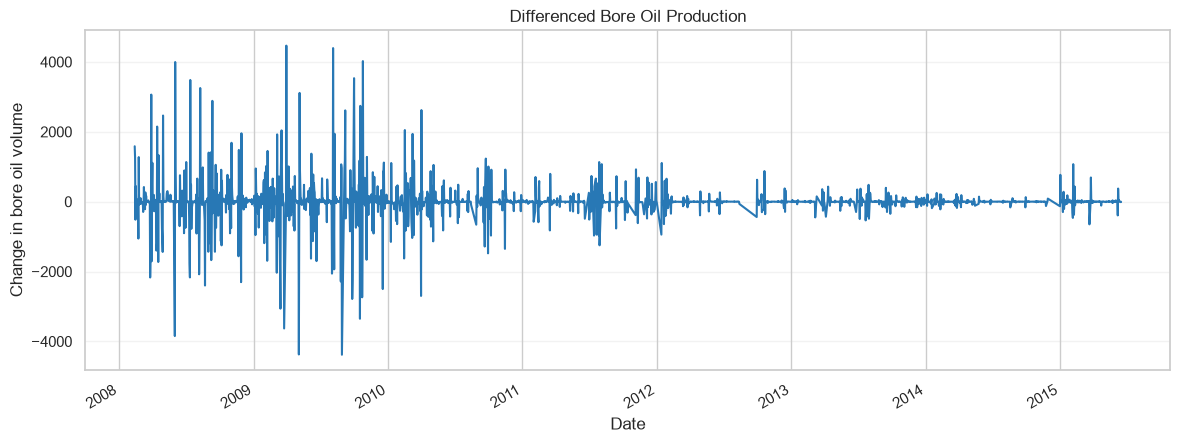

In [36]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = train_df["Differenced_BORE_OIL_VOL"].plot(figsize=(14, 5), title="Differenced Bore Oil Production", color="#2878B5", linewidth=1.5)
ax.set(xlabel="Date", ylabel="Change in bore oil volume")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/07_differenced_bore_oil_production.png", dpi=300, bbox_inches="tight")


In [37]:
diagnostic_result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])
print('ADF Statistic:', diagnostic_result[0])
print('p-value:', diagnostic_result[1])

if diagnostic_result[1] < 0.05:
    print("Data is stationary")
else:
    print("Data is non-stationary")

ADF Statistic: -16.214833054502886
p-value: 3.952310853390572e-29
Data is stationary


C:\Users\baqee\AppData\Local\Temp\ipykernel_12144\2861386677.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = sm.tsa.stattools.adfuller(train_df['Differenced_BORE_OIL_VOL'])


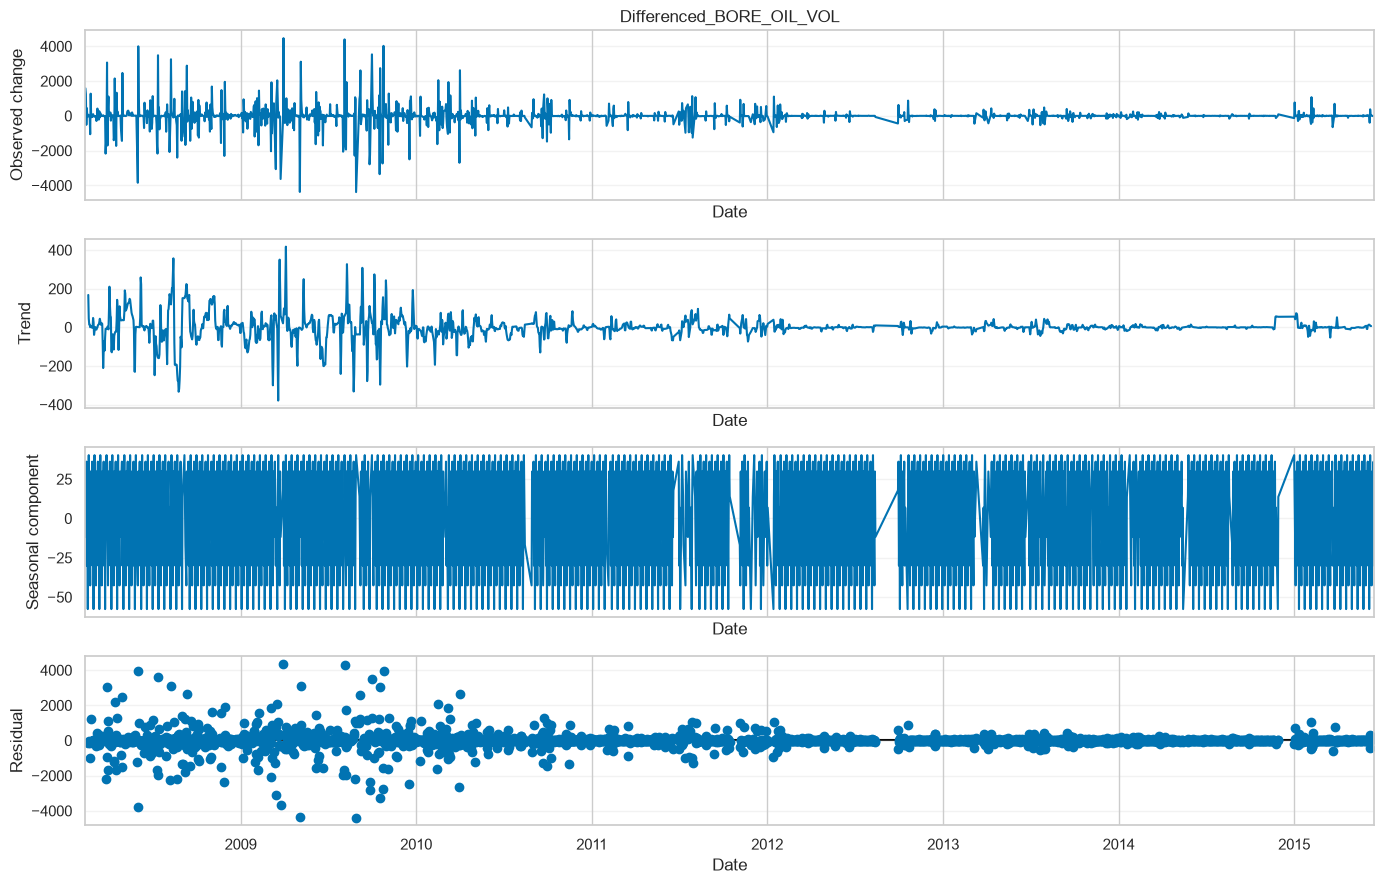

In [38]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from statsmodels.tsa.seasonal import seasonal_decompose
diagnostic_result = seasonal_decompose(train_df["Differenced_BORE_OIL_VOL"], model="additive", period=12)
fig = diagnostic_result.plot()
fig.set_size_inches(14, 9)
for ax, label in zip(fig.axes, ["Observed change", "Trend", "Seasonal component", "Residual"]):
    ax.set_xlabel("Date")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/08_seasonal_decomposition.png", dpi=300, bbox_inches="tight")
plt.show()


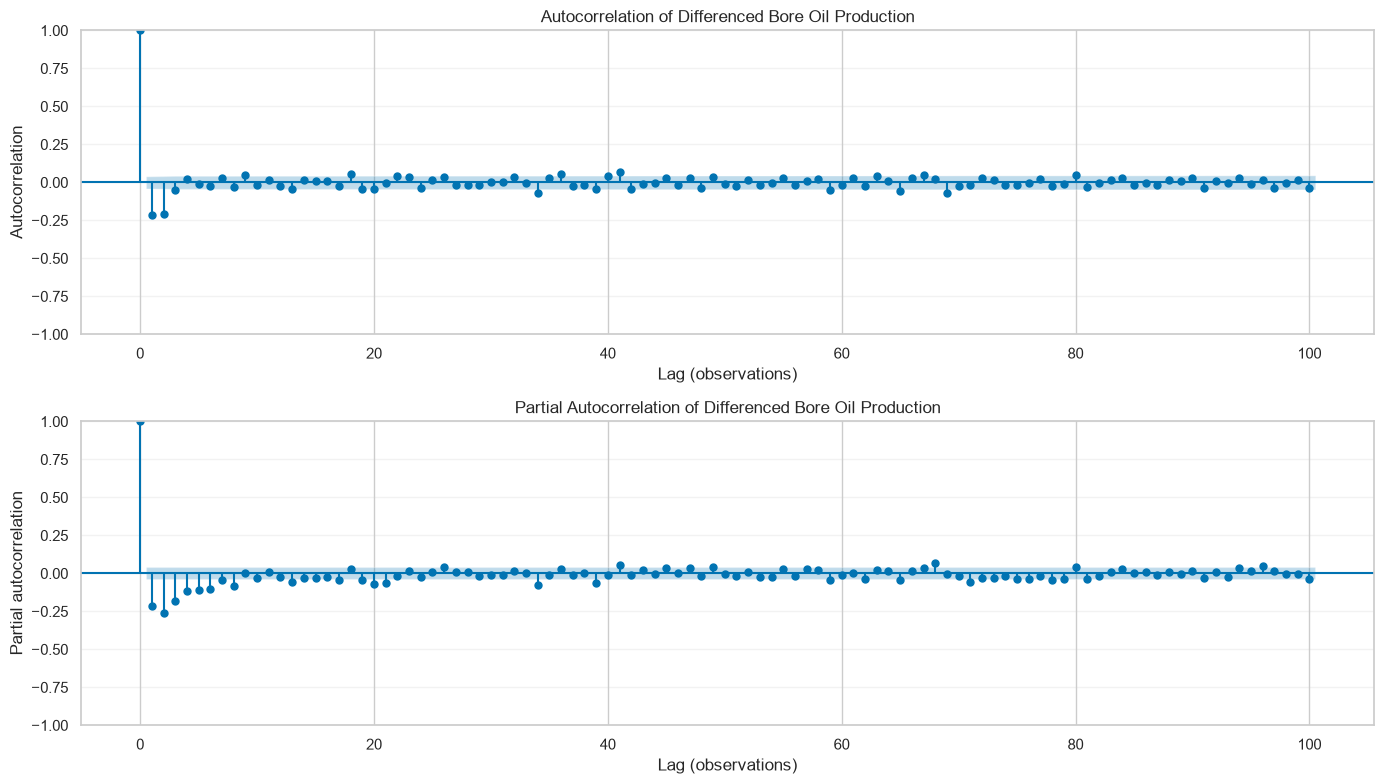

In [39]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

differenced_oil_volume = train_df["Differenced_BORE_OIL_VOL"].dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(differenced_oil_volume, lags=100, ax=axes[0], title="Autocorrelation of Differenced Bore Oil Production")
plot_pacf(differenced_oil_volume, lags=100, ax=axes[1], method="ywadjusted", title="Partial Autocorrelation of Differenced Bore Oil Production")
axes[0].set(xlabel="Lag (observations)", ylabel="Autocorrelation")
axes[1].set(xlabel="Lag (observations)", ylabel="Partial autocorrelation")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/09_acf_pacf_differenced_production.png", dpi=300, bbox_inches="tight")
plt.show()


## Forecasting Models

The notebook evaluates ARIMA, XGBoost, and LSTM. ARIMA forecasts a fixed 30-day horizon; the lag-based models use the previous 30 observed production values as input features.

### ARIMA

Fit an ARIMA(3, 1, 2) model to the cleaned training production series and forecast the next 30 days. Compare the forecast with the matching held-out observations, then inspect the fitted residual distribution.

In [40]:
training_oil_volume = train_df['BORE_OIL_VOL'].reset_index(drop=True)
model = sm.tsa.ARIMA(training_oil_volume, order=(3, 1, 2))
arima_model_fit = model.fit()

arima_forecast = arima_model_fit.forecast(steps=30)

arima_forecast.index = pd.date_range(
    start=train_df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\GitHub\.ML_Environment\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [41]:
arima_model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           BORE_OIL_VOL   No. Observations:                 2416
Model:                 ARIMA(3, 1, 2)   Log Likelihood              -18089.842
Date:                Sun, 11 Oct 2026   AIC                          36191.684
Time:                        14:24:07   BIC                          36226.421
Sample:                             0   HQIC                         36204.317
                               - 2416                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1509      0.438     -0.344      0.731      -1.010       0.708
ar.L2          0.1797      0.198      0.909      0.363      -0.208       0.567
ar.L3         -0.0372      0.044     -0.851      0.395      -0.123       0.048
ma.L1         -0.2421      0.437     -0.554      0.580      -1.098       0.614
ma.L2         -0.5102      0.367     -1.389      0.165      -1.230       0.210
sigma2      1.901e+05   1565.155    121.482      0.000    1.87e+05    1.93e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):             74706.20
Prob(Q):                              0.94   Prob(JB):                         0.00
Heteroskedasticity (H):               0.02   Skew:                            -2.53
Prob(H) (two-sided):                  0.00   Kurtosis:                        29.77
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [42]:
test_df=test_df.merge(arima_forecast.rename("Predicted_BORE_OIL_VOL"), left_index=True, right_index=True, how="left")

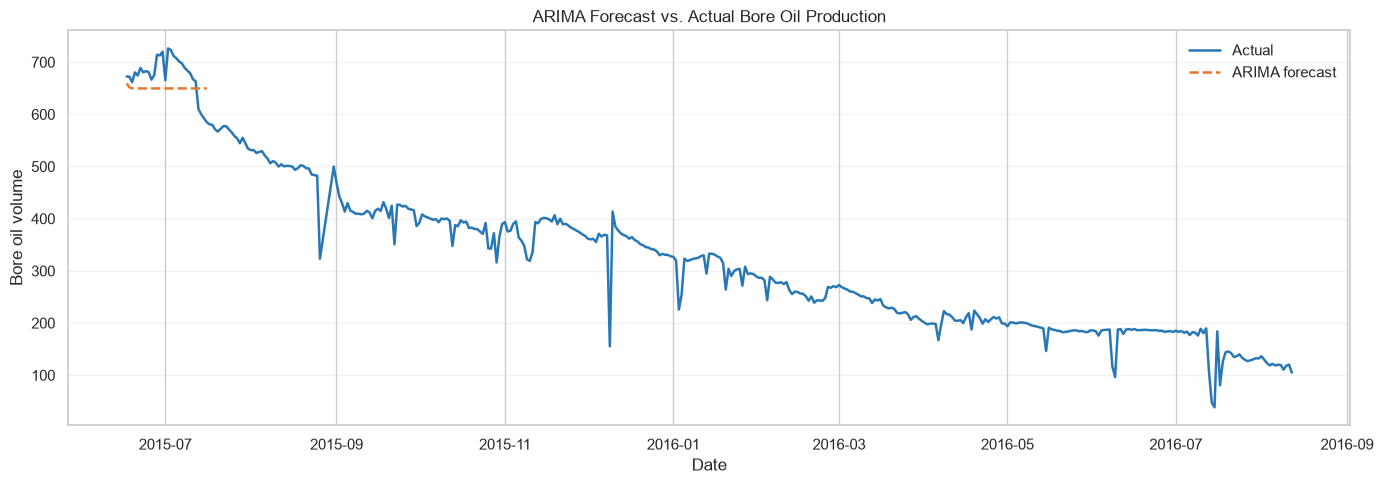

In [43]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_df.index, test_df["BORE_OIL_VOL"], label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(arima_forecast.index, arima_forecast, label="ARIMA forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="ARIMA Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/10_arima_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


In [44]:

residuals = pd.Series(test_df["BORE_OIL_VOL"] - arima_forecast, index=test_df.index, name="Residuals")


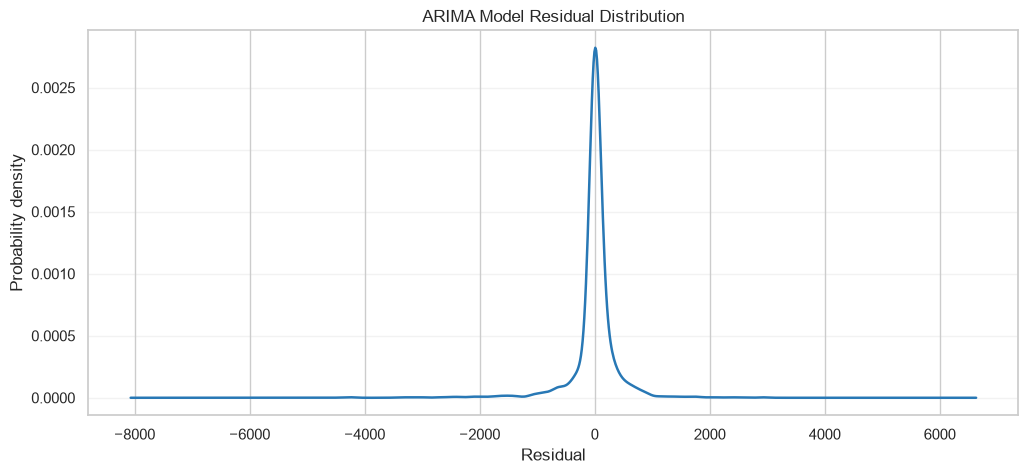

In [45]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
ax = arima_model_fit.resid.plot(kind="kde", figsize=(12, 5), title="ARIMA Model Residual Distribution", color="#2878B5", linewidth=1.8)
ax.set(xlabel="Residual", ylabel="Probability density")
ax.grid(axis="y", alpha=0.25)
os.makedirs("figures", exist_ok=True)
ax.figure.savefig("figures/11_arima_residual_distribution.png", dpi=300, bbox_inches="tight")


### XGBoost with 30-Day Lag Features

Create one feature for each of the previous 30 days. The validation interval is chronological and is used to inspect model performance; the test interval remains held out for the final comparison.

### Build Lag Features and Holdout Windows

For each date, construct `lag_1` through `lag_30`. The chronological windows below separate model fitting, validation, and final testing; no random shuffle is used.

In [46]:
def lag_features(df, n=30):
    df= df.copy()
    lag_feature_names=[]
    for i in range(1,n+1):
        df[f"lag_{i}"] = df["BORE_OIL_VOL"].shift(i)
        lag_feature_names.append(f"lag_{i}")

    return df, lag_feature_names

In [47]:
train_df, lag_feature_names= lag_features(train_df, n=30)
test_df, _= lag_features(test_df, n=30)
train_df.dropna(inplace=True)

#### Chronological Train and Validation Windows

Training data ends on 2014-07-15. Validation uses 2014-08-16 through 2015-06-16. The gap between these windows is retained as specified in the notebook.

In [48]:
training_features = train_df.loc[: "2014-07-15", lag_feature_names]
training_target = train_df.loc[: "2014-07-15", "BORE_OIL_VOL"]

validation_features = train_df.loc["2014-08-16":"2015-06-16", lag_feature_names]
validation_target = train_df.loc["2014-08-16":"2015-06-16", "BORE_OIL_VOL"]

In [49]:
training_features.loc[:,lag_feature_names].tail(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-06-16,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,204.19,...,144.14,1.30,64.25,180.26,177.92,175.82,94.40,105.51,195.86,196.51
2014-06-17,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,205.56,...,164.82,144.14,1.30,64.25,180.26,177.92,175.82,94.40,105.51,195.86
2014-06-18,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,205.52,...,189.10,164.82,144.14,1.30,64.25,180.26,177.92,175.82,94.40,105.51
2014-06-19,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,231.66,...,190.12,189.10,164.82,144.14,1.30,64.25,180.26,177.92,175.82,94.40
2014-06-20,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,205.19,...,191.25,190.12,189.10,164.82,144.14,1.30,64.25,180.26,177.92,175.82
2014-06-21,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,205.71,...,194.94,191.25,190.12,189.10,164.82,144.14,1.30,64.25,180.26,177.92
2014-06-22,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,205.41,...,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,64.25,180.26
2014-06-23,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,193.50,...,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30,64.25
2014-06-24,179.37,182.39,184.04,185.52,186.05,187.27,188.43,192.67,190.81,190.40,...,194.94,194.41,196.08,194.94,191.25,190.12,189.10,164.82,144.14,1.30


In [50]:
validation_features.loc[:,lag_feature_names].head(30)

,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30
DATEPRD,,,,,,,,,,,,,,,,,,,,,
2014-08-16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,180.22,...,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27,187.62
2014-08-17,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,174.56,...,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94,186.27
2014-08-18,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,173.47,...,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61,185.94
2014-08-19,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,170.15,...,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45,191.61
2014-08-25,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,170.25,...,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90,191.45
2014-08-26,108.65,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,175.91,...,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17,189.90
2014-08-27,187.40,108.65,10.20,174.03,175.23,175.16,175.96,175.42,174.51,175.23,...,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51,188.17
2014-08-28,184.60,187.40,108.65,10.20,174.03,175.23,175.16,175.96,175.42,174.51,...,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06,190.51
2014-08-29,190.17,184.60,187.40,108.65,10.20,174.03,175.23,175.16,175.96,175.42,...,183.88,184.75,183.95,181.66,153.93,186.18,187.63,189.06,186.07,189.06


#### Test Evaluation

The final test set follows the training period. Because lag features are built from observed test-period values, this evaluates rolling one-step-ahead predictions: each prediction can use the latest actual observations available up to that day.

In [51]:
test_df.drop(columns=["Predicted_BORE_OIL_VOL"], axis=1, inplace=True)
test_df.dropna(inplace=True)

In [52]:
test_features= test_df[lag_feature_names]
test_target= test_df["BORE_OIL_VOL"]

In [53]:
xgboost_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    objective='reg:squarederror',
    n_jobs=-1,
    random_state=42,
    # early_stopping_rounds=50
)

In [54]:
xgboost_model.fit(
    training_features,
    training_target,
    # eval_set=[
    #     (training_features, training_target), 
    #     (test_features, test_target)
    #     ],
    verbose=100  # Print progress every 100 trees,
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [55]:
xgboost_predictions = xgboost_model.predict(test_features)

In [56]:
rmse = np.sqrt(mean_squared_error(test_target, xgboost_predictions))
r2 = r2_score(test_target, xgboost_predictions)
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

Root Mean Squared Error: 36.76901995798608
R-squared: 0.9060416016347972


#### Optional Hyperparameter Search

The following cells contain an optional Optuna tuning workflow, currently commented out. The active XGBoost model uses the fixed parameters shown above.

In [57]:
# def objective(trial):

    # params = {
        # "n_estimators": trial.suggest_int(
        #     "n_estimators", 300, 1500
        # ),

        # "learning_rate": trial.suggest_float(
        #     "learning_rate", 0.01, 0.1, log=True
        # ),

        # "max_depth": trial.suggest_int(
        #     "max_depth", 2, 10
        # ),

        # "min_child_weight": trial.suggest_int(
        #     "min_child_weight", 1, 10
        # ),

        # "subsample": trial.suggest_float(
        #     "subsample", 0.6, 1.0
        # ),

        # "colsample_bytree": trial.suggest_float(
        #     "colsample_bytree", 0.6, 1.0
    #     ),

    #     "gamma": trial.suggest_float(
    #         "gamma", 0, 5
    #     ),

    #     "reg_alpha": trial.suggest_float(
    #         "reg_alpha", 1e-8, 10.0, log=True
    #     ),

    #     "reg_lambda": trial.suggest_float(
    #         "reg_lambda", 1e-8, 10.0, log=True
    #     ),

    #     "objective": "reg:squarederror",

    #     "n_jobs": -1,

    #     "random_state": 42,

    #     "early_stopping_rounds": 50
    # }

    # model = XGBRegressor(**params)

    # model.fit(
    #     x_train,
    #     y_train,
    #     eval_set=[(x_val, y_val)],
    #     verbose=False
    # )

    # val_pred = model.predict(x_val)

    # rmse = np.sqrt(
    #     mean_squared_error(y_val, val_pred)
    # )

    # return rmse

In [58]:
# study = optuna.create_study(
#     direction="minimize",
#     study_name="xgb_production_forecasting"
# )

# study.optimize(
#     objective,
#     n_trials=100
# )

In [59]:
# best_params = study.best_params.copy()

# best_params.update({
#     "objective": "reg:squarederror",
#     "n_jobs": -1,
#     "random_state": 42,
#     "early_stopping_rounds": 50
# })

# final_model = XGBRegressor(**best_params)

# final_model.fit(
#     x_train,
#     y_train,
#     eval_set=[(x_val, y_val)],
#     verbose=False
# )

In [60]:
train_df.shape

(2386, 53)

In [61]:
# test_pred = final_model.predict(x_test)

# test_rmse = np.sqrt(
#     mean_squared_error(y_test, test_pred)
# )

# test_r2 = r2_score(y_test, test_pred)
# print(f"Test RMSE: {test_rmse:.2f}")
# print(f"Test R^2: {test_r2:.2f}")

In [62]:
# print("Best validation RMSE:", study.best_value)
# print("Best parameters:")
# print(study.best_params)

# print("Train shape:", x_train.shape)
# print("Validation shape:", x_val.shape)
# print("Test shape:", x_test.shape)

In [63]:
# import joblib
# joblib.dump(final_model, "xgb_production_forecasting_model.pkl")

### LSTM with the Same Lag Windows

The LSTM receives the same 30 lag values as a sequence with one feature per time step. Input and target scalers are fitted on training data only; validation data controls early stopping, and predictions are inverse-transformed to production units before scoring.

### LSTM Training and Evaluation

Standardize lag columns and the target using training data statistics, reshape the lags into sequences, and train an LSTM with validation-based early stopping. The final cell plots test predictions in the target’s original units.

In [64]:
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

scaled_training_features = feature_scaler.fit_transform(training_features)
scaled_validation_features = feature_scaler.transform(validation_features)
scaled_test_features = feature_scaler.transform(test_features)

scaled_training_target = target_scaler.fit_transform(training_target.to_numpy().reshape(-1, 1))
scaled_validation_target = target_scaler.transform(validation_target.to_numpy().reshape(-1, 1))

training_sequences = scaled_training_features.reshape(scaled_training_features.shape[0], len(lag_feature_names), 1)
validation_sequences = scaled_validation_features.reshape(scaled_validation_features.shape[0], len(lag_feature_names), 1)
test_sequences = scaled_test_features.reshape(scaled_test_features.shape[0], len(lag_feature_names), 1)


In [65]:
from keras.callbacks import EarlyStopping

lstm_model = Sequential()
lstm_model.add(LSTM(64, input_shape=(len(lag_feature_names), 1)))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer="adam", loss="mean_squared_error")


d:\GitHub\.ML_Environment\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [76]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history = lstm_model.fit(
    training_sequences,
    scaled_training_target,
    validation_data=(validation_sequences, scaled_validation_target),
    epochs=100,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1521 - val_loss: 0.0219
Epoch 2/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1505 - val_loss: 0.0232
Epoch 3/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1468 - val_loss: 0.0235
Epoch 4/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1423 - val_loss: 0.0232
Epoch 5/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1378 - val_loss: 0.0266
Epoch 6/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1350 - val_loss: 0.0271
Epoch 7/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1305 - val_loss: 0.0283
Epoch 8/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1266 - val_loss: 0.0225
Epoch 9/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1198 - val_loss: 0.0236
Epoch 10/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1217 - val_loss: 0.0254
Epoch 11/100
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1104 - val_loss: 0.0293
Epoch 12/100
131/131 ━━━━━━━━━━━━━━━━━━━━

In [78]:
scaled_lstm_predictions = lstm_model.predict(test_sequences, verbose=0)
lstm_predictions = target_scaler.inverse_transform(scaled_lstm_predictions).ravel()

lstm_rmse = np.sqrt(mean_squared_error(test_target, lstm_predictions))
lstm_r2 = r2_score(test_target, lstm_predictions)

print(f"Root Mean Squared Error: {lstm_rmse}")
print(f"R-squared: {lstm_r2}")


Root Mean Squared Error: 74.62807825443305
R-squared: 0.6129420314208753


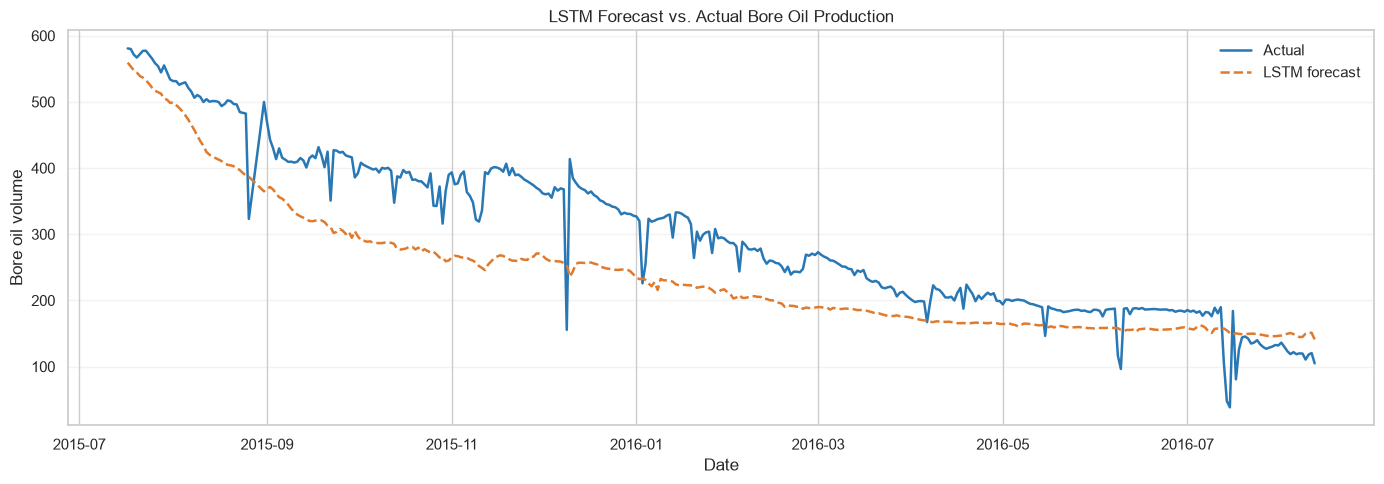

In [79]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_target.index, test_target, label="Actual", color="#2878B5", linewidth=1.8)
ax.plot(test_target.index, lstm_predictions, label="LSTM forecast", color="#E07A2D", linewidth=1.8, linestyle="--")
ax.set(title="LSTM Forecast vs. Actual Bore Oil Production", xlabel="Date", ylabel="Bore oil volume")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/13_lstm_forecast_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


## Reading the Results

Compare the reported RMSE and R² values across models on their corresponding held-out observations. Lower RMSE indicates smaller typical errors; R² compares performance with a mean-target baseline. Interpret the lag-based test metrics as rolling one-step-ahead results because actual observations from the test period become available as later lag inputs. For a fixed multi-day forecast issued once, evaluate recursively without feeding later test actuals into the input sequence.